## Лабораторная работа № 2: Генетический алгоритм для дискретной задачи с ограничениями

**ФИО**: Еремихина Мария Глебовна (Вариант: **20**)

**Целью** этой лабораторной работы является попытка спроектировать кореектное дискретное представление решения, специальные генетические операторы и методы обработки ограничений на примере задачи _«Формирование меню на неделю с ограничениями калорийности, стоимости и разнообразия»_

### 1. Ввод глобальных переменных для реализации алгоритма
Начнем с введения некоторых **ограничений** и допущений:
1. количество дней, на которые мы будем составлять расписание: `D = 7 дням`
2. количество приемов пищи за день: `M = 3 приемам`
3. для каждого продукта по ID мы можем найти: `стоимость, калории, категория`
4. введем ограничение на **калорийность** на день: $C_{min} <= C <= C_{max}$
5. ограничение по стоимости будем вводить на неделю: $Cost(X) <= Cost_{max}$

Отдельно введем ограничения на разнообразие:
1. один итот же продукт/блюдо не может встречаться `больше 2 раз за неделю`
2. в каждом дне `категории` продуктов всех 3 приемов пищи `должны быть разными`
3. за неделю мы можем использовать не менее `11` различных продуктов/блюд

В качестве представления данных (то бишь нашей особи) будем использовать `матрицу 7 * 3` (то есть 7 дней по 3 приема пищи), где каждый элемент матрицы будет содержать **идентификатор** выбранного продукта `ID`

In [103]:
NDAYS = 7
NMEALS = 3
MEALS = ["Завтрак", "Обед", "Ужин"]
MIN_CALORIES = 1300
MAX_CALORIES = 3000
MAX_COST = 8000
MIN_UNIQUE = 11
MAX_USES = 2

SEED = 42 # параметр для рандома

### 2. Генерация входных данных
Создадим синтетический набор данных на `40` продуктов/блюд, где для каждого будем хранить:
* название
* категорию
* калорийность на порцию
* стоимость одной порции
* прием пищи (чтобы в будущем было удобнее доставать необходимые продукты)

In [71]:
import random
import pandas as pd

random.seed(SEED)
COUNT = 40
categories = {
    "Крупы": (350, 650, 100, 350),
    "Мясо": (450, 800, 250, 650),
    "Рыба": (400, 750, 300, 700),
    "Овощи": (100, 300, 50, 250),
    "Фрукты": (100, 300, 50, 250),
    "Молочные": (200, 500, 100, 350),
    "Яйца": (250, 500, 100, 300),
    "Комбинированное": (400, 800, 200, 550)
}

dishes = [
    # Завтраки
    ("Овсяная каша с бананом", "Завтрак", "Крупы"),
    ("Овсяная каша с яблоком", "Завтрак", "Крупы"),
    ("Гречневая каша с молоком", "Завтрак", "Крупы"),
    ("Рисовая каша", "Завтрак", "Крупы"),
    ("Мюсли с йогуртом", "Завтрак", "Молочные"),
    ("Творог с фруктами", "Завтрак", "Молочные"),
    ("Омлет с овощами", "Завтрак", "Яйца"),
    ("Яичница с помидорами", "Завтрак", "Яйца"),
    ("Сырники", "Завтрак", "Молочные"),
    ("Бутерброды с сыром", "Завтрак", "Комбинированное"),
    ("Творожная запеканка", "Завтрак", "Молочные"),
    ("Блины с творогом", "Завтрак", "Комбинированное"),
    ("Гречневая каша с яйцом", "Завтрак", "Крупы"),
    ("Йогурт с орехами", "Завтрак", "Молочные"),
    # Обеды
    ("Курица с гречкой", "Обед", "Мясо"),
    ("Курица с рисом", "Обед", "Мясо"),
    ("Индейка с овощами", "Обед", "Мясо"),
    ("Говядина с картофелем", "Обед", "Мясо"),
    ("Свинина с рисом", "Обед", "Мясо"),
    ("Лосось с рисом", "Обед", "Рыба"),
    ("Тунец с овощами", "Обед", "Рыба"),
    ("Хек с картофелем", "Обед", "Рыба"),
    ("Скумбрия с овощами", "Обед", "Рыба"),
    ("Чечевица с овощами", "Обед", "Крупы"),
    ("Фасоль с рисом", "Обед", "Крупы"),
    ("Паста с курицей", "Обед", "Комбинированное"),
    ("Куриный суп с овощами", "Обед", "Комбинированное"),
    ("Говядина с гречкой", "Обед", "Мясо"),
    # Ужины
    ("Курица с овощами", "Ужин", "Мясо"),
    ("Индейка с брокколи", "Ужин", "Мясо"),
    ("Говядина с овощами", "Ужин", "Мясо"),
    ("Лосось с овощами", "Ужин", "Рыба"),
    ("Хек с овощами", "Ужин", "Рыба"),
    ("Тунец с салатом", "Ужин", "Рыба"),
    ("Овощное рагу с курицей", "Ужин", "Комбинированное"),
    ("Гречка с грибами", "Ужин", "Крупы"),
    ("Чечевица с овощами", "Ужин", "Крупы"),
    ("Омлет с овощами", "Ужин", "Яйца"),
    ("Запеканка из овощей", "Ужин", "Овощи"),
    ("Рыба с картофелем", "Ужин", "Рыба")
]

In [15]:
products = []
for dish_id, (name, meal, category) in enumerate(dishes):
    min_cal, max_cal, min_price, max_price = categories[category]
    calories = random.randint(min_cal, max_cal)
    price = round(random.uniform(min_price, max_price), 2)
    products.append({"id": dish_id, "name": name, "meal": meal, "category": category, "calories": calories, "price": price})
products_df = pd.DataFrame(products)
products_df

,id,name,meal,category,calories,price
0,0,Овсяная каша с бананом,Завтрак,Крупы,605,465.53
1,1,Овсяная каша с яблоком,Завтрак,Крупы,441,400.11
2,2,Гречневая каша с молоком,Завтрак,Крупы,564,576.63
3,3,Рисовая каша,Завтрак,Крупы,343,258.61
4,4,Мюсли с йогуртом,Завтрак,Молочные,458,418.72
5,5,Творог с фруктами,Завтрак,Молочные,373,529.84
6,6,Омлет с овощами,Завтрак,Яйца,551,351.68
7,7,Яичница с помидорами,Завтрак,Яйца,308,191.87
8,8,Сырники,Завтрак,Молочные,363,372.42
9,9,Бутерброды с сыром,Завтрак,Комбинированное,574,575.59


Напомним структуру одной _особи_: у нас **7** дней в неделю и **3** приема пищи, а, следовательно, для одной особи нам нужно **21** ген, каждый из которых будет представлять собой `ID продукта/блюда` на i-ый день и j-ый прием пищи

Распределим все продукты/блюды на группы _в зависимости от приема пищи_, чтобы в дальнейшим спокойно брать блюда необходимого вида

In [16]:
dishes_by_meal = {
    meal: products_df.loc[products_df["meal"] == meal, "id"].tolist()
    for meal in MEALS
}
for meal, dish_ids in dishes_by_meal.items():
    print(f"{meal}: {len(dish_ids)} блюд")

Завтрак: 14 блюд
Обед: 14 блюд
Ужин: 12 блюд


### 3. Создание индивида
Пришло время написать функцию, которая будет рандомно **создавать** нам **особь** на основе нашего текущего набора блюд, используя рандом

In [18]:
def create_individual():
    individual = []
    for i in range(NDAYS):
        day = []
        for meal in MEALS:
            dish_id = random.choice(dishes_by_meal[meal])
            day.append(dish_id)
        individual.append(day)
    return individual

individual = create_individual()
individual

[[2, 26, 37],
 [4, 15, 31],
 [1, 22, 34],
 [9, 23, 37],
 [3, 26, 36],
 [6, 21, 35],
 [4, 27, 37]]

Прежде чем переходить дальше, рассмотрим какие особи нас _устраивают_, а какие 100% нам _не подходят_ по описанным выше критериям (буквально небольшой примерчик: по 2 на каждый из случаев)

    invalid_1 = [[0, 14, 28], [1, 15, 29], [0, 14, 28], [1, 15, 29], [0, 14, 28], [1, 15, 29], [0, 14, 28]]
! Слишком плохая **вариативность** + не выполняется условие на суммарное количество **уникальных** блюд

    invalid_2 = [[3, 23, 28], [1, 21, 39], [7, 19, 37], [0, 20, 28], [4, 15, 29], [1, 19, 36], [4, 23, 37]]
! Совпадение **категорий** продукта в некоторых днях

В качестве корректных возьмем те, которые получились у меня в процессе повторных запусков _генетического алгоритма_:

    correct_1 = [[7, 25, 36], [8, 25, 35], [3, 17, 34], [10, 24, 34], [6, 27, 35], [7, 17, 36], [9, 24, 37]]
    correct_2 = [[10, 17, 36], [13, 25, 35], [10, 17, 37], [7, 24, 34], [13, 23, 37], [7, 25, 36], [6, 24, 34]]

### 4. Расчет фитнес-функции
Ну а теперь пора вспомнить все основные моменты генетического алгоритма и зададим целевую функцию, которую мы будем стараться увести в ноль и которая будет выглядеть следующим образом:

$f(INDIVID) = \Delta UNIQUE * 5000 + \Delta COUNT * 5000 + \Delta CALORIES * 10 + \Delta COST * 20$ + $CATEGORY * 5000$

In [115]:
from collections import Counter

def fitness(individual):
    total_penalty = 0
    dish_ids = [dish_id for day in individual for dish_id in day]
    unique_count = len(set(dish_ids))
    if unique_count < MIN_UNIQUE:
        total_penalty += (MIN_UNIQUE - unique_count) * 5000
    counts = Counter(dish_ids)
    for count in counts.values():
        if count > MAX_USES:
            total_penalty += (count - MAX_USES) * 5000
    for day in individual:
        daily_calories = sum(products_df.loc[dish_id, "calories"] for dish_id in day)
        if daily_calories < MIN_CALORIES:
            total_penalty += (MIN_CALORIES - daily_calories) * 10
        elif daily_calories > MAX_CALORIES:
            total_penalty += (daily_calories - MAX_CALORIES) * 10
    total_cost = sum(products_df.loc[dish_id, "price"] for dish_id in dish_ids)
    if total_cost > MAX_COST:
        total_penalty += (total_cost - MAX_COST) * 20
    for day in individual:
        categories = [products_df.loc[dish_id, "category"] for dish_id in day]
        if len(set(categories)) < NMEALS:
            total_penalty += 5000
    return total_penalty

### 5. Реализация выбора и скрещивания
Естественно для того, чтобы минимизировать `total_penalty` по целевой функции нам надо придумать алгоритм для отбора особей на каждом из заходов, давайте возьмем тот ж алгоритм, что и был в прошлый раз: **турнирный отбор**

`Турнирный отбор` предполагает, что мы берем какое-то количество особей и из них выбираем ту, у которой фитнес-функция будет меньше, в качестве длины батча будем использовать `k=3`

In [58]:
def tournament_selection(population, tournament_size=3):
    candidates = random.sample(population, min(tournament_size, len(population)))
    return min(candidates, key=fitness)

Также нам необходимо выбрать метод для скрещивания выбранных родителей, чтобы сохранить по-максимуму свойства обеих особей. Так как у нас матричное представление особей, то мы можем сделать следующий принцип, носящий название **одноточечное скрещивание по дням**: выбираем случайный день и тогда до него берем все от первого родителя, а далее только от второго, а потом **наоборот**

In [59]:
def crossover(parent1, parent2):
    point = random.randint(1, NDAYS - 1)
    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]
    return child1, child2

### 6. Мутация
Ну как же без **мутаций** (случайное изменение генов особи), но мы не можем просто бездумно добавлять какое-либо число к текущему гену, так как он является `ID` блюда, а также мы должны _интеллектуально_ заменять завтрак на завтрак, обед на обед и так далее, так что кроме вероятности надо еще учитывать все эти правила

In [60]:
MUTATION_RATE = 0.1 # процент изменения особи
def mutate(individual):
    individual = [day[:] for day in individual]
    for day_index in range(NDAYS):
        for meal_index, meal in enumerate(MEALS):
            if random.random() < MUTATION_RATE:
                old_dish = individual[day_index][meal_index]
                candidates = [dish_id for dish_id in dishes_by_meal[meal] if dish_id != old_dish]
                if candidates:
                    individual[day_index][meal_index] = random.choice(candidates)
    return individual

Но после скрещиваний и мутаций у нас может _нарушится правила_ и чтобы ускорить процесс схождения к локальному минимуму допишем функцию `repair_individual`, которая будет ремонтировать текущую особь, но для упрощения кода самой функции, напишем несколько **вспомогательных**:
1. `get_stats(menu)` - функция, позволяющая посмотреть текущие ошибки для особи
2. `is_correct(menu)` - функция, которая возвращает истину, если все ошибки равны нулю, то есть ошибки отсутствуют и мы можем ее не менять

In [180]:
def get_stats(menu):
        dish_ids = [dish_id for day in menu for dish_id in day]
        counts = Counter(dish_ids)
        daily_calories = [sum(products_df.loc[dish_id, "calories"] for dish_id in day) for day in menu]
        total_cost = sum(products_df.loc[dish_id, "price"] for dish_id in dish_ids)
        category_errors = sum(len({products_df.loc[dish_id, "category"] for dish_id in day}) < NMEALS for day in menu)
        repeat_errors = sum(max(0, count - MAX_USES) for count in counts.values())
        calorie_errors = sum(max(0, MIN_CALORIES - calories) + max(0, calories - MAX_CALORIES) for calories in daily_calories)
        cost_error = max(0, total_cost - MAX_COST)
        diversity_error = max(0, MIN_UNIQUE - len(set(dish_ids)))
        return category_errors * 5000 + repeat_errors * 5000 + calorie_errors * 10 + cost_error * 20 + diversity_error * 5000

def repair_individual(individual, max_attempts=10):
    best = [day[:] for day in individual]
    for i in range(max_attempts):
        if get_stats(best) == 0:
            return best
        errors = get_stats(best)
        current_error = errors
        improved = False
        positions = [(day_index, meal_index) for day_index in range(NDAYS) for meal_index in range(NMEALS)]
        random.shuffle(positions)
        for day_index, meal_index in positions:
            old_dish = best[day_index][meal_index]
            meal = MEALS[meal_index]
            other_categories = {products_df.loc[best[day_index][j], "category"] for j in range(NMEALS) if j != meal_index}
            candidates = [dish_id for dish_id in dishes_by_meal[meal] if dish_id != old_dish and products_df.loc[dish_id, "category"] not in other_categories]
            random.shuffle(candidates)
            candidates = candidates[:5]
            for new_dish in candidates:
                candidate = [day[:] for day in best]
                candidate[day_index][meal_index] = new_dish
                new_error = get_stats(candidate)
                if new_error < current_error:
                    best = candidate
                    improved = True
                    break
            if improved:
                break
        if not improved:
            break
    if get_stats(best):
        return best
    return None

### 7. Полный цикл алгоритма
```mermaid
graph TD
    A[Создание начальной популяции] --> B[Оценка особей]
    B --> C{Условие остановки выполнено?}
    C -- Да --> G[Вывод лучшего решения]
    C -- Нет --> D[Отбор родителей и сохранение элиты]
    D --> E[Скрещивание]
    E --> F[Мутация]
    F --> H[Формирование нового поколения]
    H --> B
```

Для начала просто посмотрим на популяцию и оценим порядок, который получается при применении фитнес-функции на особь, то есть посмотрим на **лучшее** и **среднее** значения

In [164]:
POP_SIZE = 50
population = [create_individual() for i in range(POP_SIZE)]
fitness_scores = [fitness(individual) for individual in population]

print("Лучшее значение фитнес-функции:", round(min(fitness_scores), 2))
print("Среднее значение функции:", round(sum(fitness_scores) / len(fitness_scores), 2))

Лучшее значение фитнес-функции: 91938.6
Среднее значение функции: 146388.85


In [183]:
GENERATIONS = 100

def genetic_algorithm():
    population = [create_individual() for i in range(POP_SIZE)]
    best_individual = min(population, key=fitness)
    best_score = fitness(best_individual)
    history = []
    for generation in range(GENERATIONS):
        population.sort(key=fitness)
        new_population = [[day[:] for day in population[0]]] # элитизм - сохранение лучшей особи
        while len(new_population) < POP_SIZE:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child1, child2 = crossover(parent1, parent2)
            child1 = mutate(child1)
            child2 = mutate(child2)
            new_population.append(child1)
            if len(new_population) < POP_SIZE:
                new_population.append(child2)
        population = new_population
        current_best = min(population, key=fitness)
        current_score = fitness(current_best)
        if current_score < best_score:
            best_individual = [day[:] for day in current_best]
            best_score = current_score
        history.append(best_score)
        if best_score == 0:
            break
    return best_individual, best_score, history

In [187]:
best_menu, best_score, history = genetic_algorithm()

In [188]:
days = []
for day_index, day in enumerate(best_menu, start=1):
    row = {"День": day_index}
    daily_calories = 0
    daily_cost = 0
    for meal_index, dish_id in enumerate(day):
        dish = products_df.loc[dish_id]
        row[MEALS[meal_index]] = dish["name"] + f" ({dish['id']})"
        daily_calories += dish["calories"]
        daily_cost += dish["price"]
    row["Калории за день"] = daily_calories
    row["Стоимость за день"] = round(daily_cost, 2)
    days.append(row)

menu_df = pd.DataFrame(days)
menu_df

,День,Завтрак,Обед,Ужин,Калории за день,Стоимость за день
0,1,Мюсли с йогуртом (4),Фасоль с рисом (24),Омлет с овощами (37),1190,1032.35
1,2,Яичница с помидорами (7),Говядина с картофелем (17),Чечевица с овощами (36),1463,1000.81
2,3,Сырники (8),Фасоль с рисом (24),Рыба с картофелем (39),1513,1320.06
3,4,Йогурт с орехами (13),Паста с курицей (25),Гречка с грибами (35),1491,1057.06
4,5,Яичница с помидорами (7),Курица с рисом (15),Чечевица с овощами (36),1458,1119.47
5,6,Творожная запеканка (10),Паста с курицей (25),Омлет с овощами (37),1514,1144.78
6,7,Йогурт с орехами (13),Курица с рисом (15),Гречка с грибами (35),1463,1321.82


Вот наше лучшее меню, но хочется же посмотреть все ли _критерии_ (наши поставленные) он _соблел_, так что ниже как раз соответствующая **проверка**

In [189]:
def print_report(best):
    dish_ids = [dish_id for day in best for dish_id in day]
    total_cost = sum(products_df.loc[dish_id, "price"] for dish_id in dish_ids)
    daily_calories = [sum(products_df.loc[dish_id, "calories"] for dish_id in day) for day in best]
    unique_count = len(set(dish_ids))
    counts = Counter(dish_ids)
    different_categories = all(len({products_df.loc[dish_id, "category"] for dish_id in day}) == NMEALS for day in best)
    checks = [("Недельный бюджет", total_cost <= MAX_COST, f"{total_cost:.2f} / {MAX_COST}"),
              ("Разнообразие блюд", unique_count >= MIN_UNIQUE, f"{unique_count} / минимум {MIN_UNIQUE}"),
              ("Частота повторений", all(count <= MAX_USES for count in counts.values()), f"не более {MAX_USES} раз на блюдо"),
              ("Калорийность", all(MIN_CALORIES <= c <= MAX_CALORIES for c in daily_calories), f"{MIN_CALORIES}–{MAX_CALORIES} ккал в день"),
              ("Разные категории в течение дня", different_categories, "все 3 категории должны различаться")]
    print("Все ли параметры и критерии выполнились для лучшего решения?")
    for name, passed, value in checks:
        status = "ЕСТЬ:" if passed else "НЕТ:"
        print(f"{status} {name}: {value}")

print_report(best_menu)

Все ли параметры и критерии выполнились для лучшего решения?
ЕСТЬ: Недельный бюджет: 7996.35 / 8000
ЕСТЬ: Разнообразие блюд: 13 / минимум 11
ЕСТЬ: Частота повторений: не более 2 раз на блюдо
НЕТ: Калорийность: 1300–3000 ккал в день
ЕСТЬ: Разные категории в течение дня: все 3 категории должны различаться


### 8. Генетический алгоритм со штрафом и ремонтом
Давай теперь вспомним, что мы еще писали функцию **ремонта** для особи, так что попробуем построить тот же алгоритм, но теперь с ремонтом, вдруг все станет в разы лучше)

In [190]:
def genetic_algorithm_with_repair():
    population = [create_individual() for i in range(POP_SIZE)]
    best_individual = min(population, key=fitness)
    best_score = fitness(best_individual)
    history = []
    for generation in range(GENERATIONS):
        population.sort(key=fitness)
        new_population = [[day[:] for day in population[0]]] # элитизм - сохранение лучшей особи
        while len(new_population) < POP_SIZE:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child1, child2 = crossover(parent1, parent2)
            child1 = mutate(child1)
            child2 = mutate(child2)
            child1 = repair_individual(child1)
            child2 = repair_individual(child2)
            if child1 is None:
                child1 = create_individual()
            if child2 is None:
                child2 = create_individual()
            new_population.append(child1)
            if len(new_population) < POP_SIZE:
                new_population.append(child2)
        population = new_population
        current_best = min(population, key=fitness)
        current_score = fitness(current_best)
        if current_score < best_score:
            best_individual = [day[:] for day in current_best]
            best_score = current_score
        history.append(best_score)
        if best_score == 0:
            break
    return best_individual, best_score, history

In [191]:
best_menu_with_repair, best_score_with_repair, history_with_repair = genetic_algorithm_with_repair()

In [192]:
days = []
for day_index, day in enumerate(best_menu_with_repair, start=1):
    row = {"День": day_index}
    daily_calories = 0
    daily_cost = 0
    for meal_index, dish_id in enumerate(day):
        dish = products_df.loc[dish_id]
        row[MEALS[meal_index]] = dish["name"] + f" ({dish['id']})"
        daily_calories += dish["calories"]
        daily_cost += dish["price"]
    row["Калории за день"] = daily_calories
    row["Стоимость за день"] = round(daily_cost, 2)
    days.append(row)

menu_df_with_repair = pd.DataFrame(days)
menu_df_with_repair

,День,Завтрак,Обед,Ужин,Калории за день,Стоимость за день
0,1,Творожная запеканка (10),Курица с рисом (15),Гречка с грибами (35),1479,1342.84
1,2,Яичница с помидорами (7),Говядина с картофелем (17),Чечевица с овощами (36),1463,1000.81
2,3,Йогурт с орехами (13),Паста с курицей (25),Гречка с грибами (35),1491,1057.06
3,4,Яичница с помидорами (7),Фасоль с рисом (24),Овощное рагу с курицей (34),1331,941.11
4,5,Омлет с овощами (6),Говядина с картофелем (17),Чечевица с овощами (36),1706,1160.62
5,6,Творожная запеканка (10),Фасоль с рисом (24),Овощное рагу с курицей (34),1570,1102.20
6,7,Рисовая каша (3),Паста с курицей (25),Омлет с овощами (37),1310,1050.43


In [193]:
print_report(best_menu_with_repair)

Все ли параметры и критерии выполнились для лучшего решения?
ЕСТЬ: Недельный бюджет: 7655.07 / 8000
ЕСТЬ: Разнообразие блюд: 13 / минимум 11
ЕСТЬ: Частота повторений: не более 2 раз на блюдо
ЕСТЬ: Калорийность: 1300–3000 ккал в день
ЕСТЬ: Разные категории в течение дня: все 3 категории должны различаться


### 9. Сравнение генетического алгоритма с и без ремонта
Чтобы понять, насколько нам вообще важен ремонт после создания детей и мутирования, сравним итоги алгоритма без и с ремонтом **5** раз (несколько раз надо для того, чтобы немножко приуменьшить влияние рандома для алгоритмов)

In [194]:
N_RUNS = 5
def run_experiments():
    results = {"Обычный генетический алгоритм": [], "Генетический алгоритм с ремонтом": []}
    histories = {"Обычный генетический алгоритм": [], "Генетический алгоритм с ремонтом": []}
    algorithms = {"Обычный генетический алгоритм": genetic_algorithm, "Генетический алгоритм с ремонтом": genetic_algorithm_with_repair}

    for name, algorithm in algorithms.items():
        print(f"\nЗапуск экспериментов: {name}")
        for run in range(N_RUNS):
            best_menu, best_score, history = algorithm()
            valid = get_stats(best_menu) == 0
            results[name].append({"Запуск": run + 1, "Fitness": best_score, "Допустимое решение": valid})
            histories[name].append(history)
            print(f"Запуск {run + 1}/{N_RUNS}: "
                f"fitness = {best_score:.2f}, "
                f"допустимое = {valid}")
    return results, histories
results, histories = run_experiments()


Запуск экспериментов: Обычный генетический алгоритм
Запуск 1/5: fitness = 210.00, допустимое = False
Запуск 2/5: fitness = 2100.00, допустимое = False
Запуск 3/5: fitness = 780.00, допустимое = False
Запуск 4/5: fitness = 370.00, допустимое = False
Запуск 5/5: fitness = 1410.00, допустимое = False

Запуск экспериментов: Генетический алгоритм с ремонтом
Запуск 1/5: fitness = 0.00, допустимое = True
Запуск 2/5: fitness = 0.00, допустимое = True
Запуск 3/5: fitness = 0.00, допустимое = True
Запуск 4/5: fitness = 0.00, допустимое = True
Запуск 5/5: fitness = 0.00, допустимое = True


Ну и оформим это в табличку, чтобы четко понимать, что **с ремонтом** мы получаем _лучший_ генетический алгоритм

In [196]:
summary = []
for name, runs in results.items():
    df = pd.DataFrame(runs)
    summary.append({
        "Алгоритм": name,
        "Лучший fitness": df["Fitness"].min(),
        "Средний fitness": df["Fitness"].mean(),
        "Медианный fitness": df["Fitness"].median(),
        "Допустимые решения, %": 100 * df["Допустимое решение"].mean()
    })

summary_df = pd.DataFrame(summary).round(3)
summary_df

,Алгоритм,Лучший fitness,Средний fitness,Медианный fitness,"Допустимые решения, %"
0,Обычный генетический алгоритм,210,974.0,780.0,0.0
1,Генетический алгоритм с ремонтом,0,0.0,0.0,100.0


Не забудем провизуализировать то, что сейчас получили, то есть продемонстрируем сходимость алгоритмов к минимуму фитнес-функции

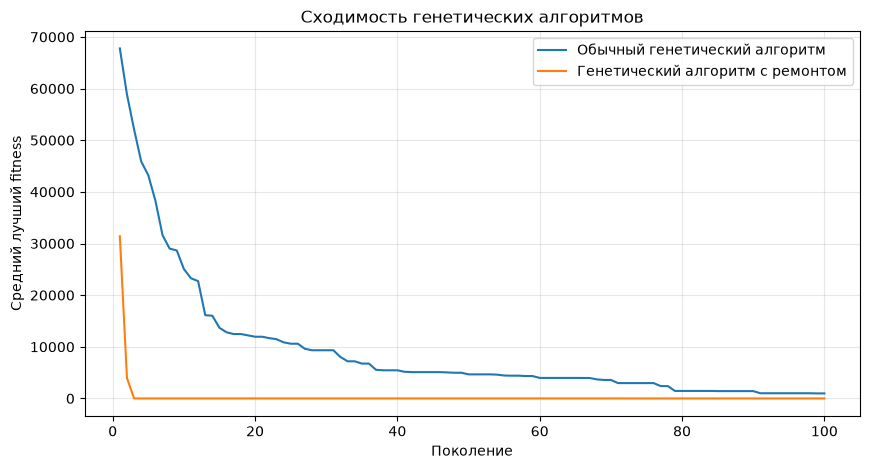

In [199]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))
for name, runs in histories.items():
    padded_histories = [history + [history[-1]] * (GENERATIONS - len(history)) for history in runs]
    mean_history = np.mean(padded_histories, axis=0)
    plt.plot(range(1, GENERATIONS + 1), mean_history, label=name)

plt.xlabel("Поколение")
plt.ylabel("Средний лучший fitness")
plt.title("Сходимость генетических алгоритмов")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 10. Сравнение различных функций для реализации мутации
Рассмотрим в качестве мутации две различные вариации:
1. **случайная** замена одного из блюд
2. чуть более умная замена, которая еще учитывает и категорию по дню

In [202]:
def mutate_random(individual):
    child = [day[:] for day in individual]
    day_index = random.randrange(NDAYS)
    meal_index = random.randrange(NMEALS)
    meal = MEALS[meal_index]
    candidates = dishes_by_meal[meal]
    child[day_index][meal_index] = random.choice(candidates)
    return child

In [203]:
def mutate_category(individual):
    child = [day[:] for day in individual]
    day_index = random.randrange(NDAYS)
    meal_index = random.randrange(NMEALS)
    meal = MEALS[meal_index]
    other_categories = {products_df.loc[child[day_index][j], "category"] for j in range(NMEALS) if j != meal_index}
    candidates = [dish_id for dish_id in dishes_by_meal[meal] if products_df.loc[dish_id, "category"] not in other_categories]
    if candidates:
        child[day_index][meal_index] = random.choice(candidates)
    return child

Ну а теперь сравним оба генетического алгоритма, чтобы понять, насколько влияет **появление ограничения** на категорию для мутаций и посмотрим на средние показатели обоих алгоритмов

In [209]:
import time
def genetic_algorithm(mutation_operator):
    population = [create_individual() for i in range(POP_SIZE)]
    best_individual = min(population, key=fitness)
    best_score = fitness(best_individual)
    history = []
    for generation in range(GENERATIONS):
        population.sort(key=fitness)
        new_population = [[day[:] for day in population[0]]]
        while len(new_population) < POP_SIZE:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child1, child2 = crossover(parent1, parent2)
            child1 = mutation_operator(child1)
            child2 = mutation_operator(child2)
            new_population.append(child1)
            if len(new_population) < POP_SIZE:
                new_population.append(child2)
        population = new_population
        current_best = min(population, key=fitness)
        current_score = fitness(current_best)
        if current_score < best_score:
            best_individual = [day[:] for day in current_best]
            best_score = current_score
        history.append(best_score)
        if best_score == 0:
            break
    return best_individual, best_score, history

def run_mutation_experiments():
    results = {"Случайная замена": [], "Замена с учётом категорий": []}
    histories = {"Случайная замена": [], "Замена с учётом категорий": []}
    operators = {"Случайная замена": mutate_random, "Замена с учётом категорий": mutate_category}
    for name, operator in operators.items():
        print(f"\nЭксперимент: {name}")
        for run in range(N_RUNS):
            start = time.time()
            best_menu, best_score, history = genetic_algorithm(operator)
            elapsed = time.time() - start
            valid = get_stats(best_menu) == 0
            results[name].append({"Запуск": run + 1, "Fitness": best_score, "Допустимое решение": valid, "Время, сек": round(elapsed, 2)})
            histories[name].append(history)
    return results, histories

results, histories = run_mutation_experiments()
for name, runs in results.items():
    df = pd.DataFrame(runs)
    display(df)
    print(f"\n{name}")
    print(f"Доля допустимых решений: "
          f"{df['Допустимое решение'].mean() * 100:.1f}%")
    print(f"Лучший fitness: {df['Fitness'].min():.2f}")
    print(f"Среднее время: {df['Время, сек'].mean():.2f} сек")

,Запуск,Fitness,Допустимое решение,"Время, сек"
0,1,370,False,12.18
1,2,0,True,11.51
2,3,0,True,7.40
3,4,210,False,11.86
4,5,210,False,11.83



Случайная замена
Доля допустимых решений: 40.0%
Лучший fitness: 0.00
Среднее время: 10.96 сек


,Запуск,Fitness,Допустимое решение,"Время, сек"
0,1,0,True,5.40
1,2,0,True,5.23
2,3,0,True,8.18
3,4,0,True,6.25
4,5,0,True,4.74



Замена с учётом категорий
Доля допустимых решений: 100.0%
Лучший fitness: 0.00
Среднее время: 5.96 сек


### 11. Сравнение генетического алгоритма со случайным поиском

In [212]:
def random_search(time_limit):
    start = time.time()
    best_menu = None
    best_score = float("inf")
    history = []
    while time.time() - start < time_limit:
        menu = create_individual()
        score = fitness(menu)
        if score < best_score:
            best_menu = menu
            best_score = score
        history.append(best_score)
        if score == 0:
            best_menu = menu
            best_score = 0
            break
    return best_menu, best_score, history, time.time() - start

def compare_ga_with_random_search():
    results = {"Генетический алгоритм": [], "Случайный поиск": []}
    for run in range(N_RUNS):
        start = time.time()
        ga_menu, ga_score, ga_history = genetic_algorithm(mutate_random)
        ga_time = time.time() - start
        results["Генетический алгоритм"].append({"Запуск": run + 1, "Fitness": ga_score, "Допустимое решение": get_stats(ga_menu) == 0, "Время, сек": round(ga_time, 2)})
        rs_menu, rs_score, rs_history, rs_time = random_search(ga_time)
        results["Случайный поиск"].append({"Запуск": run + 1, "Fitness": rs_score, "Допустимое решение": get_stats(rs_menu) == 0, "Время, сек": round(rs_time, 2)})
    for name, data in results.items():
        df = pd.DataFrame(data)
        print(f"\n{name}")
        display(df)
        print(f"Доля допустимых решений: "
              f"{df['Допустимое решение'].mean() * 100:.1f}%")
        print(f"Лучший fitness: {df['Fitness'].min():.2f}")
        print(f"Средний fitness: {df['Fitness'].mean():.2f}")
        print(f"Среднее время: {df['Время, сек'].mean():.2f} сек")
    return results

comparison_results = compare_ga_with_random_search()


Генетический алгоритм


,Запуск,Fitness,Допустимое решение,"Время, сек"
0,1,210,False,12.65
1,2,0,True,9.00
2,3,0,True,8.46
3,4,0,True,5.77
4,5,0,True,6.44


Доля допустимых решений: 80.0%
Лучший fitness: 0.00
Средний fitness: 42.00
Среднее время: 8.46 сек

Случайный поиск


,Запуск,Fitness,Допустимое решение,"Время, сек"
0,1,47804.0,False,12.65
1,2,46758.8,False,9.00
2,3,34056.4,False,8.46
3,4,28177.4,False,5.77
4,5,45455.2,False,6.44


Доля допустимых решений: 0.0%
Лучший fitness: 28177.40
Средний fitness: 40450.36
Среднее время: 8.46 сек
